**Netflix Project**

**SVD** -> Singular Value Decomposition

`A=UΣV^T`

*   A - Large complicated puzzle (matrix A)

SVD breaks down A(puzzle) into manageable sections:

*   U - Shows the patterns in how people put the puzzle pieces together (user preference).

*   Σ - Highlights which patterns are the most important (key features).

*   V^T - Shows the patterns in the puzzle pieces themselves (item similarities).



Ashok - Action and Sci-fi

Sandip - Romantic comedies and dramas

Maruthi - Mix of action and drama

Zahid - Sci-fi and thrillers



          Action Romantic Scifi Drama Thriller
Ashok   5  1  5  2  3

Sandip  1  5  2  5  1

Maruthi 4  3  3  4  2

Zahid  3  1  5  2  5

**Link for the dataset :** https://drive.google.com/drive/folders/1lgXm5Lyqjdkisn1G9c-MqaeLT4boNIzg

In [ ]:
import numpy as np
import pandas as pd

In [ ]:
df=pd.read_csv('/content/drive/MyDrive/Data for Files/combinedNetflixData.txt',names=['CustID','Ratings'],usecols=[0,1],header=None)

In [ ]:
df

,CustID,Ratings
0,1:,NaN
1,1488844,3.0
2,822109,5.0
3,885013,4.0
4,30878,4.0
...,...,...
24058258,2591364,2.0
24058259,1791000,2.0
24058260,512536,5.0
24058261,988963,3.0


**These are the rating provided by the users for a given movie, that is actually combined with the customer ID.**

In [ ]:
#shape of the data
df.shape

(24058263, 2)

How many movies we are having in total?

In [ ]:
total_movie_count=df.isnull().sum()['Ratings']

In [ ]:
print(f'The number of movies that are present are: {total_movie_count}')

The number of movies that are present are: 4499


In [ ]:
#How many customers we are having?
customer_count=df['CustID'].nunique()-total_movie_count
customer_count

470758

In [ ]:
df['CustID'].nunique()

475257

In [ ]:
475257-470758

4499

In [ ]:
df_nan=pd.DataFrame(pd.isnull(df['Ratings']))

In [ ]:
df_nan

,Ratings
0,True
1,False
2,False
3,False
4,False
...,...
24058258,False
24058259,False
24058260,False
24058261,False


In [ ]:
df_nan=df_nan[df_nan['Ratings']==True]
df_nan

,Ratings
0,True
548,True
694,True
2707,True
2850,True
...,...
24046714,True
24047329,True
24056849,True
24057564,True


In [ ]:
df.iloc[24057834]

,24057834
CustID,4499:
Ratings,NaN


**How many ratings we are dealing**

In [ ]:
total_ratings=df['Ratings'].count()-total_movie_count

In [ ]:
total_ratings

24049265

**Individual Ratings**

In [ ]:
df['Ratings'].value_counts()

,count
Ratings,
4.0,8085741
3.0,6904181
5.0,5506583
2.0,2439073
1.0,1118186


In [ ]:
stars=df.groupby('Ratings')['Ratings'].agg(['count'])

In [ ]:
stars

,count
Ratings,
1.0,1118186
2.0,2439073
3.0,6904181
4.0,8085741
5.0,5506583


In [ ]:
import matplotlib.pyplot as plt

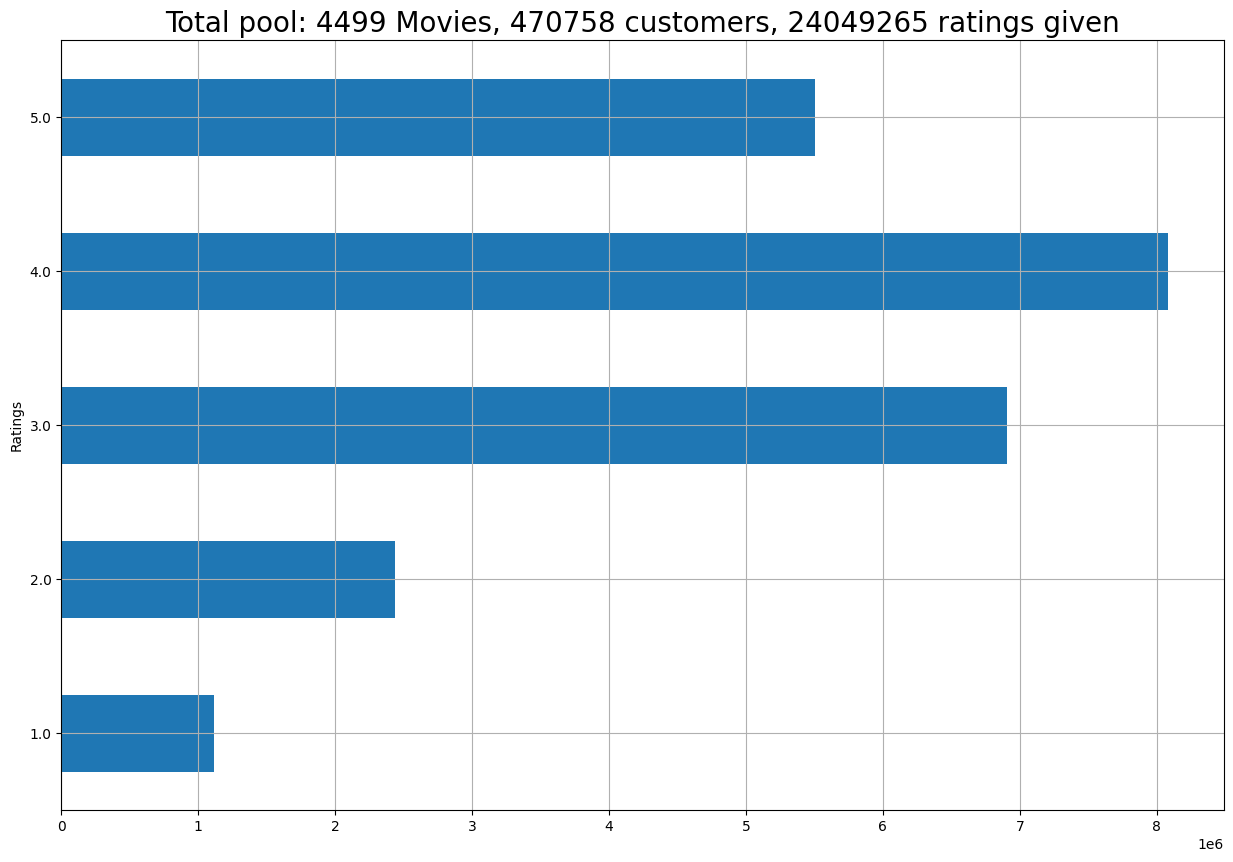

In [ ]:
ax=stars.plot(kind='barh',legend=False,figsize=(15,10))
plt.title(f'Total pool: {total_movie_count} Movies, {customer_count} customers, {total_ratings} ratings given',fontsize=20)
plt.grid(True)

**Segregation of the data**

In [ ]:
#separating the movie ID's from CustID col
current_movie_id=None
movie_id=[]

for cust_id in df['CustID']:
  if ':' in cust_id:
    current_movie_id=int(cust_id.replace(':',''))
  movie_id.append(current_movie_id)

In [ ]:
len(movie_id)

24058263

In [ ]:
movie_id[-1]

4499

In [ ]:
temp=df.copy()

In [ ]:
temp['Movie_Id']=movie_id

In [ ]:
temp=temp[temp['Ratings'].notna()]

In [ ]:
temp

,CustID,Ratings,Movie_Id
1,1488844,3.0,1
2,822109,5.0,1
3,885013,4.0,1
4,30878,4.0,1
5,823519,3.0,1
...,...,...,...
24058258,2591364,2.0,4499
24058259,1791000,2.0,4499
24058260,512536,5.0,4499
24058261,988963,3.0,4499
